# Sorting and graph search on NYC taxi data

This notebook walks through the analysis behind the README: loading and cleaning ~100,000 NYC yellow-taxi trips, computing trip statistics, benchmarking six sorting algorithms written from scratch, and analysing the zone-to-zone trip network.

All the logic lives in `src/`; the notebook only calls it and shows the results. Benchmarks are produced by `benchmark.py` (about 3 minutes) and loaded here from `results/`.

In [1]:
import pandas as pd
from IPython.display import Image

from src.taxi_data import (read_trips, read_zones, data_quality, valid_values, summary,
                           plausible_speeds, count_trips_from)
from src.graph import build_graph, components

trips = read_trips("data/trips_100k.csv")
zones = read_zones("data/taxi_zone_lookup.csv")
print(f"{len(trips):,} trips loaded")

100,000 trips loaded


## 1. Data quality

Raw TLC data contains records that can't be real: negative fares (refunds and corrections), trips that end before they start, and trips whose *average* speed over the whole journey would exceed 100 km/h. They are counted here and excluded from the statistics, not silently dropped.

In [2]:
pd.Series(data_quality(trips), name="records").to_frame()

,records
trips,100000
missing_passenger_count,3447
negative_fare,613
non_positive_duration,78
implausible_speed,133


## 2. Trip statistics

In [3]:
stats = {label: summary(valid_values(trips, field))
         for label, field in [("Passengers", "passengers"), ("Fare ($)", "fare"),
                              ("Tip ($)", "tip"), ("Total paid ($)", "total")]}
speeds = plausible_speeds(trips)
stats["Average speed (km/h)"] = summary(speeds)
pd.DataFrame(stats).T.round(2)

,min,max,mean,n
Passengers,0.0,8.00,1.40,96553.0
Fare ($),0.0,600.00,14.88,99387.0
Tip ($),0.0,100.00,2.72,99992.0
Total paid ($),0.0,601.00,21.72,99380.0
Average speed (km/h),0.0,97.11,19.12,99789.0


In [4]:
airports_and_landmarks = {1: "Newark Airport", 132: "JFK Airport", 138: "LaGuardia Airport",
                          43: "Central Park", 74: "East Harlem North"}
pd.Series(count_trips_from(trips, airports_and_landmarks), name="pickups").to_frame()

,pickups
Newark Airport,35
JFK Airport,4709
LaGuardia Airport,2728
Central Park,1696
East Harlem North,265


## 3. Sorting benchmark

Six algorithms implemented in `src/sorting.py`, each tested against Python's `sorted()` in `tests/`. They sort trip totals (shuffled) at sizes from 500 to 99,000. Each point is the median of several runs. The quadratic algorithms stop at 20,000 trips: beyond that a single run takes minutes.

In [5]:
runtime = pd.read_csv("results/sorting_runtime.csv")
runtime.pivot(index="n", columns="algorithm", values="seconds").round(4)

algorithm,Bubble sort,Heap sort,Insertion sort,Merge sort,Quick sort,Selection sort
n,,,,,,
500,0.0069,0.0006,0.0033,0.0005,0.0003,0.0034
1000,0.0305,0.0014,0.0146,0.0011,0.0008,0.0139
2000,0.1267,0.0028,0.0541,0.0021,0.0013,0.0559
5000,0.7269,0.0090,0.3698,0.0067,0.0037,0.3396
10000,3.4685,0.0210,1.4971,0.0155,0.0081,1.7824
20000,15.3758,0.0495,5.9512,0.0344,0.0166,11.7406
50000,NaN,0.1410,NaN,0.0938,0.0572,NaN
99000,NaN,0.3642,NaN,0.2127,0.1085,NaN


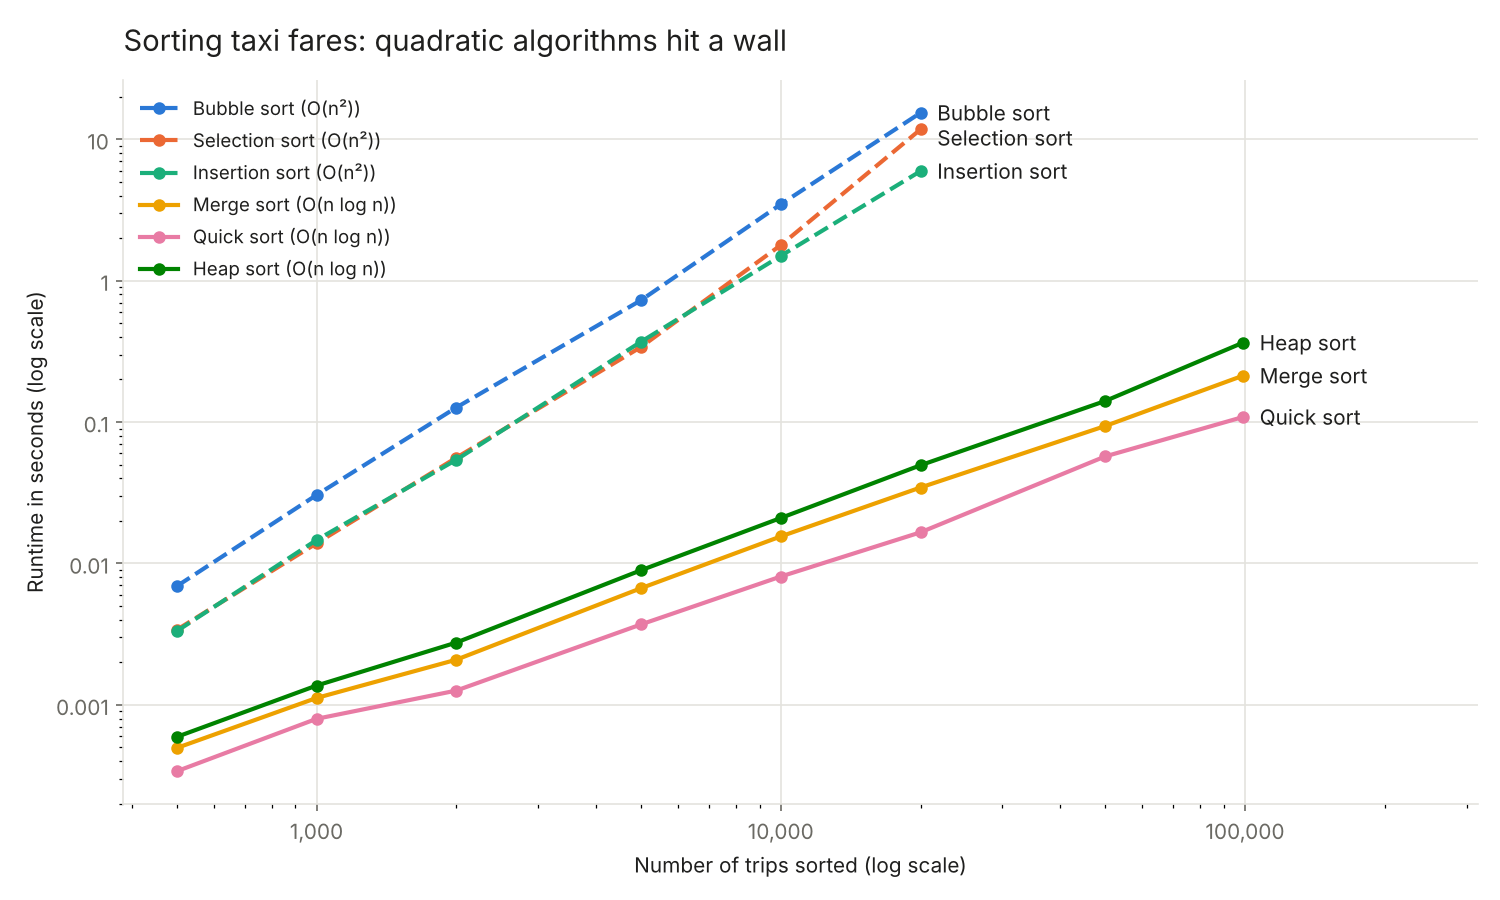

In [6]:
Image("images/runtime_vs_size.png")

Doubling the input from 10,000 to 20,000 trips multiplies bubble sort's runtime by about 4 (the signature of O(n²)), while merge sort's only roughly doubles. Extrapolating, bubble sort would need around 6 minutes for the full 100,000 trips that quick sort handles in about 0.1 seconds.

### Does the shape of the data change the winner?

Same size (10,000 values), three kinds of input.

In [7]:
shape = pd.read_csv("results/input_shape.csv")
shape.pivot(index="algorithm", columns="input", values="seconds").round(4)

input,Already sorted (descending),Passenger counts (7 distinct values),Random fares
algorithm,,,
Bubble sort,0.0005,2.6164,3.3785
Insertion sort,0.0007,0.6060,1.5179
Merge sort,0.0088,0.0118,0.0156
Quick sort,0.0050,0.0010,0.0082


- On **already-sorted** data, bubble sort (with its early exit) and insertion sort finish in under a millisecond, beating every O(n log n) algorithm.
- On **passenger counts** (only a handful of distinct values), the three-way quick sort gets about 8× faster, because equal values are grouped in a single pass.
- Complexity classes describe the worst or average case; real data can sit far from it.

## 4. The trip network

Each taxi zone is a node and each pair of zones with at least one trip between them is an edge, weighted by the number of trips. Connected components are found with our own DFS and BFS and checked against NetworkX.

In [8]:
rows = []
for label, path in [("5,000", "data/trips_5k.csv"), ("30,000", "data/trips_30k.csv"), ("100,000", "data/trips_100k.csv")]:
    g = build_graph((t.pickup_zone, t.dropoff_zone) for t in read_trips(path))
    comps = sorted((len(c) for c in components(g, "dfs")), reverse=True)
    assert comps == sorted((len(c) for c in components(g, "bfs")), reverse=True)
    rows.append({"trips": label, "zones": g.number_of_nodes(), "routes": g.number_of_edges(),
                 "components": len(comps), "component sizes": comps})
pd.DataFrame(rows)

,trips,zones,routes,components,component sizes
0,"5,000",184,1626,3,"[181, 2, 1]"
1,"30,000",240,3326,3,"[236, 2, 2]"
2,"100,000",253,5234,1,[253]


With 5,000 trips a few outlying zones look cut off from the rest of the city; with 100,000 every zone is reachable from every other. The "isolated" zones were a sampling artefact, not a property of the city, which matters for any conclusion drawn from a small sample of a network.

In [9]:
pd.read_csv("results/graph_search.csv").assign(milliseconds=lambda d: (d.seconds * 1000).round(3))

,method,seconds,milliseconds
0,Own DFS,0.000228,0.228
1,Own BFS,0.000227,0.227
2,NetworkX,0.000180,0.180


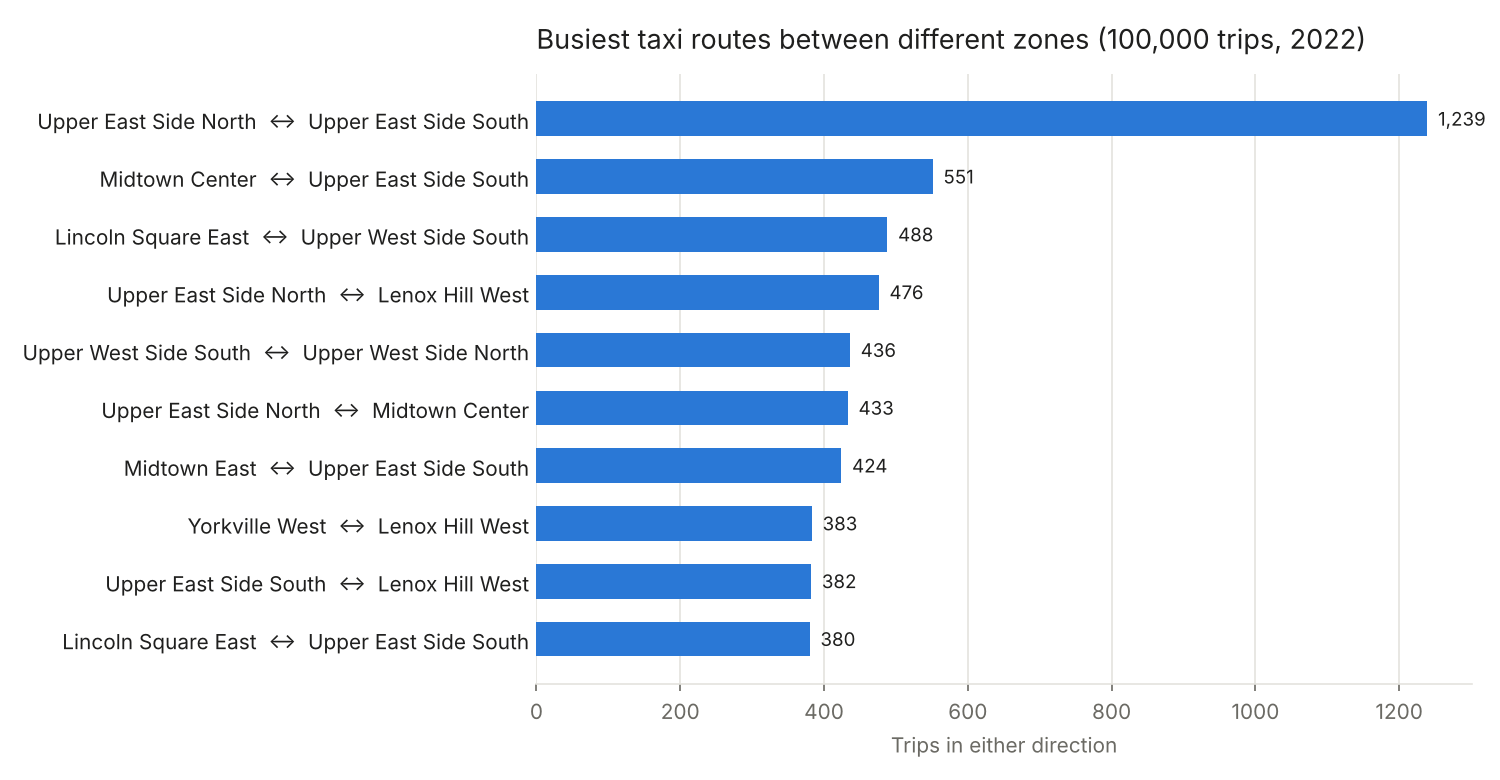

In [10]:
Image("images/top_routes.png")